In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import matplotlib
print(matplotlib.get_backend())
%matplotlib inline

Agg


In [7]:
df = pd.read_csv("fft_signal_dataset.csv")
df.head()

,time_seconds,true_signal,noise,noisy_signal
0,0.000,0.000000,-0.292237,-0.292237
1,0.002,0.512853,0.494222,1.007075
2,0.004,0.877004,1.341189,2.218193
3,0.006,1.015931,-1.499229,-0.483298
4,0.008,0.959143,0.503340,1.462483


In [47]:
t = df["time_seconds"].values
true_signal = df["true_signal"].values
noisy_signal = df["noisy_signal"].values
fs = 500
N = len(noisy_signal)

frequencies = np.fft.rfftfreq(N, d=1/fs)

print(frequencies[:5])
print("Sampling frequency:", fs)
print("Number of samples:", N)

[0.   0.25 0.5  0.75 1.  ]
Sampling frequency: 500
Number of samples: 2000


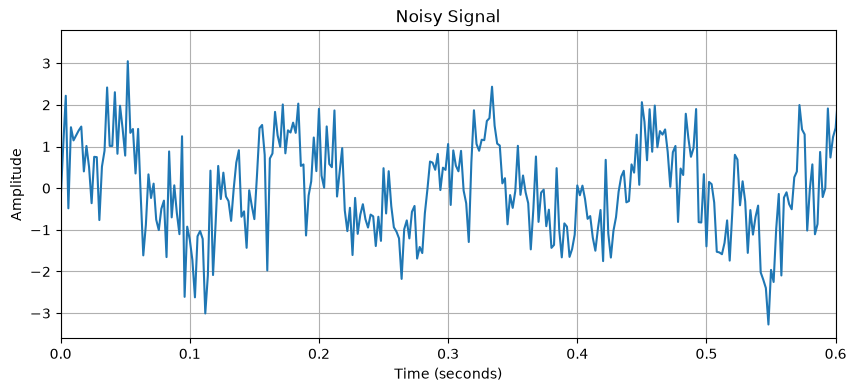

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(t, noisy_signal)
plt.xlim(0, 0.6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Noisy Signal")
plt.grid()
plt.show()

In [42]:
fft_values = np.fft.rfft(noisy_signal)
print(fft_values[:5])

[ 35.57076059 +0.j         -14.17550154 +8.52464678j
  -7.47001427+23.31041254j  -5.1423694 +10.59694959j
  18.57870503+19.67481659j]


In [44]:
magnitude = np.abs(fft_values)

print(magnitude[:5])

[35.57076059 16.54129519 24.47808092 11.77876494 27.06042661]


In [45]:
amplitude_spectrum = magnitude / N
amplitude_spectrum[1:-1] *= 2

print(amplitude_spectrum[:5])

[0.01778538 0.0165413  0.02447808 0.01177876 0.02706043]


In [48]:
index = np.argmin(np.abs(frequencies - 7))

print("Index:", index)
print("Frequency:", frequencies[index])
print("Amplitude:", amplitude_spectrum[index])

Index: 28
Frequency: 7.0
Amplitude: 0.9755401684670656


In [49]:
for target in [7, 25, 60]:
    index = np.argmin(np.abs(frequencies - target))
    print(target, amplitude_spectrum[index])

7 0.9755401684670656
25 0.6002234656189523
60 0.3627873691169314


In [50]:
for target in [7, 25, 60]:
    index = np.argmin(np.abs(frequencies - target))
    print("Frequency:", frequencies[index], "Hz")
    print("Amplitude:", amplitude_spectrum[index])
    print()

Frequency: 7.0 Hz
Amplitude: 0.9755401684670656

Frequency: 25.0 Hz
Amplitude: 0.6002234656189523

Frequency: 60.0 Hz
Amplitude: 0.3627873691169314



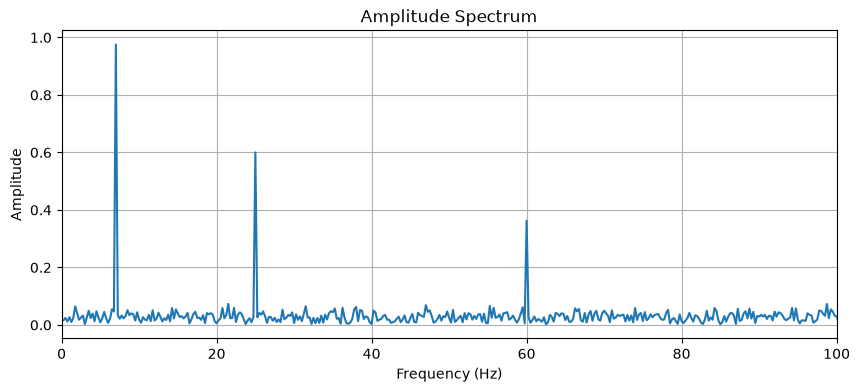

In [52]:
median_amplitude = np.median(amplitude_spectrum)
threshold = 8 * median_amplitude

print("Median amplitude:", median_amplitude)
print("Threshold:", threshold)

Median amplitude: 0.02578942080997141
Threshold: 0.20631536647977128


In [53]:
peaks = []

for i in range(1, len(amplitude_spectrum) - 1):
    if (amplitude_spectrum[i] > amplitude_spectrum[i - 1]
        and amplitude_spectrum[i] > amplitude_spectrum[i + 1]
        and amplitude_spectrum[i] > threshold):
        peaks.append(i)

peak_frequencies = frequencies[peaks]

print("Detected peak frequencies:")
print(peak_frequencies)

Detected peak frequencies:
[ 7. 25. 60.]


In [54]:
for i in peaks:
    print("Frequency:", frequencies[i], "Hz",
          "| Amplitude:", amplitude_spectrum[i])

Frequency: 7.0 Hz | Amplitude: 0.9755401684670656
Frequency: 25.0 Hz | Amplitude: 0.6002234656189523
Frequency: 60.0 Hz | Amplitude: 0.3627873691169314


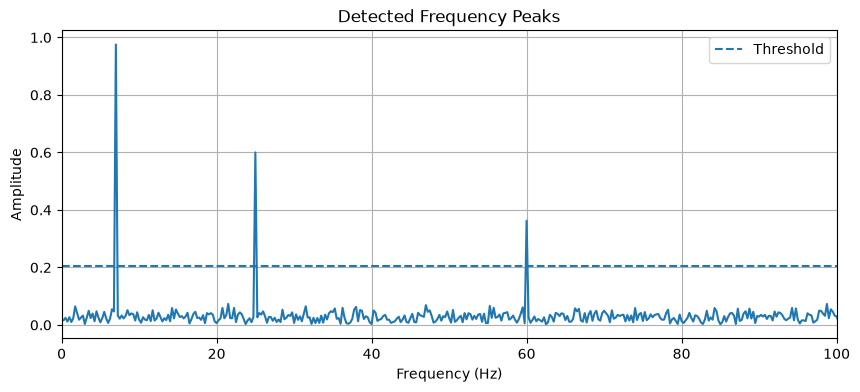

In [55]:
plt.figure(figsize=(10, 4))
plt.plot(frequencies, amplitude_spectrum)
plt.axhline(threshold, linestyle="--", label="Threshold")
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("Detected Frequency Peaks")
plt.legend()
plt.grid()
plt.show()

In [56]:
cutoff = 80

filtered_fft = fft_values.copy()
filtered_fft[frequencies > cutoff] = 0

In [57]:
removed = np.sum(frequencies > cutoff)

print("Cutoff frequency:", cutoff, "Hz")
print("Frequency bins removed:", removed)

Cutoff frequency: 80 Hz
Frequency bins removed: 680


In [58]:
filtered_signal = np.fft.irfft(filtered_fft, n=N)

In [59]:
print("Original samples:", len(noisy_signal))
print("Filtered samples:", len(filtered_signal))
print(filtered_signal[:5])

Original samples: 2000
Filtered samples: 2000
[0.25143211 0.73454284 0.98446207 1.05286077 1.06272221]


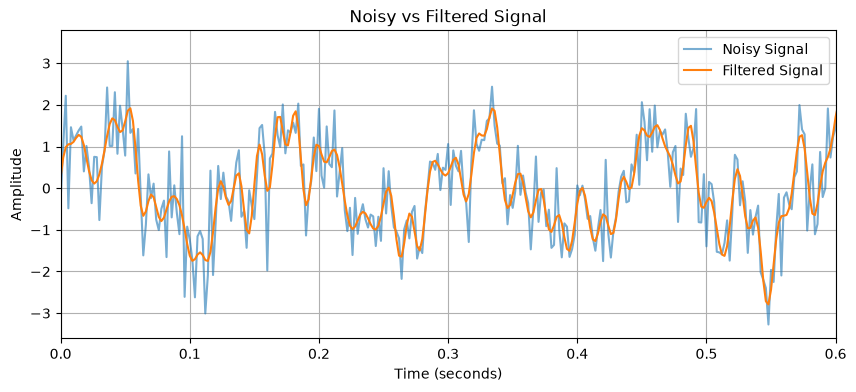

In [60]:
plt.figure(figsize=(10, 4))

plt.plot(t, noisy_signal, label="Noisy Signal", alpha=0.6)
plt.plot(t, filtered_signal, label="Filtered Signal")

plt.xlim(0, 0.6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Noisy vs Filtered Signal")
plt.legend()
plt.grid()
plt.show()

In [61]:
rms_before = np.sqrt(
    np.mean((noisy_signal - true_signal) ** 2)
)

print("RMS Error Before Filtering:", rms_before)

RMS Error Before Filtering: 0.7001834189422476


In [64]:
rms_after = np.sqrt(
    np.mean((filtered_signal - true_signal) ** 2)
)

print("RMS Error After Filtering:", rms_after)

RMS Error After Filtering: 0.3989014417939178


In [65]:
print("Before:", rms_before)
print("After:", rms_after)

Before: 0.7001834189422476
After: 0.3989014417939178


In [66]:
noise_before = noisy_signal - true_signal

In [67]:
snr_before = 10 * np.log10(
    np.mean(true_signal ** 2) /
    np.mean(noise_before ** 2)
)
print("SNR Before Filtering:", snr_before, "dB")

SNR Before Filtering: 1.7954106234362448 dB


In [68]:
noise_after = filtered_signal - true_signal

In [69]:
snr_after = 10 * np.log10(
    np.mean(true_signal ** 2) /
    np.mean(noise_after ** 2)
)
print("SNR After Filtering:", snr_after, "dB")

SNR After Filtering: 6.682334943091153 dB


In [70]:
print("RMS Before:", rms_before)
print("RMS After:", rms_after)

print("SNR Before:", snr_before, "dB")
print("SNR After:", snr_after, "dB")

RMS Before: 0.7001834189422476
RMS After: 0.3989014417939178
SNR Before: 1.7954106234362448 dB
SNR After: 6.682334943091153 dB


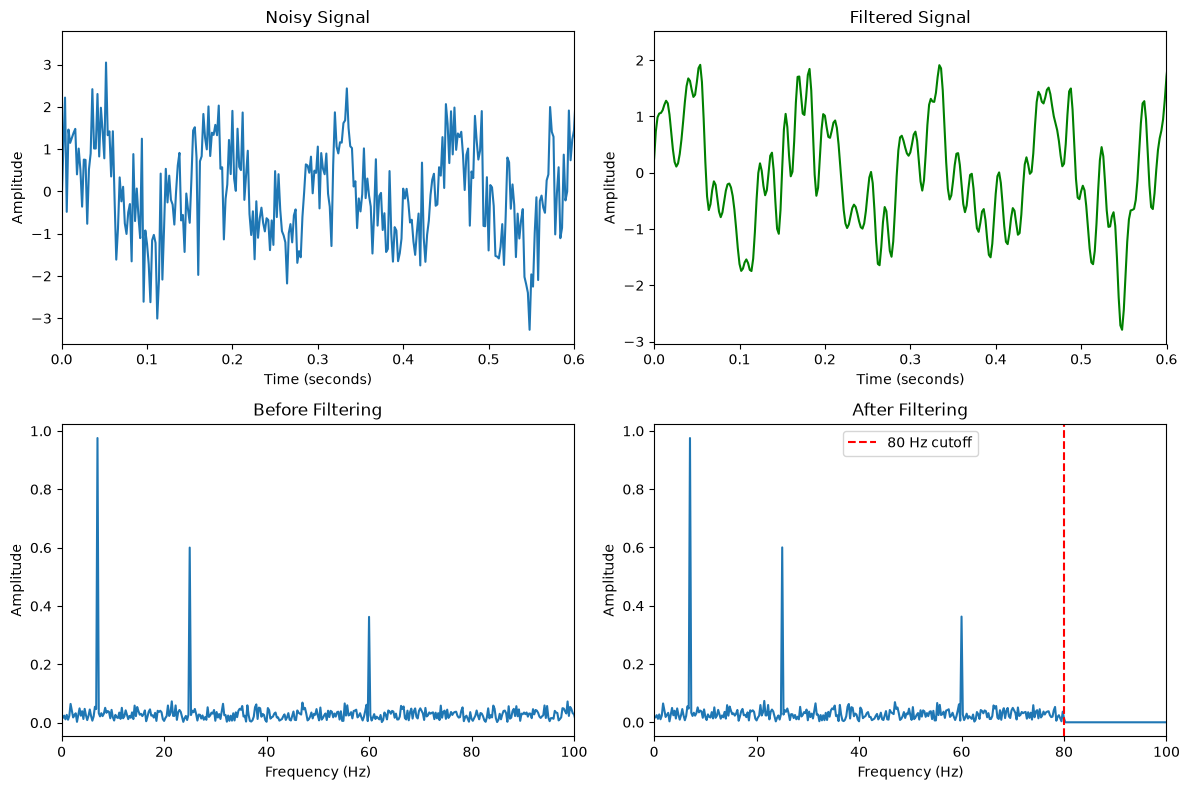

In [88]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. Noisy signal
ax[0, 0].plot(t, noisy_signal)
ax[0, 0].set_title("Noisy Signal")
ax[0, 0].set_xlim(0, 0.6)
ax[0, 0].set_xlabel("Time (seconds)")
ax[0, 0].set_ylabel("Amplitude")

# 2. Filtered signal
ax[0, 1].plot(t, filtered_signal, color="green")
ax[0, 1].set_title("Filtered Signal")
ax[0, 1].set_xlim(0, 0.6)
ax[0, 1].set_xlabel("Time (seconds)")
ax[0, 1].set_ylabel("Amplitude")

# 3. Frequency spectrum before filtering
ax[1, 0].plot(frequencies, amplitude_spectrum)
ax[1, 0].set_title("Before Filtering")
ax[1, 0].set_xlim(0, 100)
ax[1, 0].set_xlabel("Frequency (Hz)")
ax[1, 0].set_ylabel("Amplitude")

# 4. Frequency spectrum after filtering
ax[1, 1].plot(frequencies, filtered_amplitude)
ax[1, 1].axvline(80, linestyle="--", color="red",
                 label="80 Hz cutoff")
ax[1, 1].set_title("After Filtering")
ax[1, 1].set_xlim(0, 100)
ax[1, 1].set_xlabel("Frequency (Hz)")
ax[1, 1].set_ylabel("Amplitude")
ax[1, 1].legend()

plt.tight_layout()
fig.savefig("chart.png", dpi=120, bbox_inches="tight")
plt.show()

In [84]:
import os

print(os.path.exists("chart.png"))

True


In [85]:
results = {
    "rms_before": float(rms_before),
    "rms_after": float(rms_after),
    "snr_before_db": float(snr_before),
    "snr_after_db": float(snr_after),
    "cutoff_frequency_hz": 80
}

In [86]:
with open("results.json", "w") as file:
    json.dump(results, file, indent=4)

In [87]:
with open("results.json", "r") as file:
    saved_results = json.load(file)

print(saved_results)

{'rms_before': 0.7001834189422476, 'rms_after': 0.3989014417939178, 'snr_before_db': 1.7954106234362448, 'snr_after_db': 6.682334943091153, 'cutoff_frequency_hz': 80}
